## Step 1: Project Setup & Understanding the Data

In this step we will:
- Import the required libraries
- Load the dataset
- Examine its structure, data types, missing values and basic statistics
- Write down our first observations

### 1.1 Import Libraries

We use the standard data analysis stack:
- `pandas` → data manipulation and analysis
- `numpy` → numerical operations
- `matplotlib` & `seaborn` → visualization

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings for better readability
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

# Style for plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('Set2')

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.2 Load the Dataset

The data is located at: `DataProject/data/train.csv`


In [2]:
# Load the data
# Relative path from the notebooks folder
df = pd.read_csv('../data/train.csv')

print("Dataset loaded successfully!")
print(f"Shape of the dataset: {df.shape[0]} rows × {df.shape[1]} columns")

Dataset loaded successfully!
Shape of the dataset: 9800 rows × 18 columns


### 1.3 First Look at the Data

Let's examine the first few rows, column names, data types and missing values.

In [3]:
# Display the first 5 rows
print("First 5 rows of the dataset:")
df.head()

First 5 rows of the dataset:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.00,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.00,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.00,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37


In [4]:
# Column names
print("Column names:")
print(df.columns.tolist())

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales']


In [5]:
# Data types and non-null counts
print("Dataset Info:")
df.info()

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: fl

In [6]:
# Missing values summary
print("Missing values per column:")
missing = df.isnull().sum()
missing_df = pd.DataFrame({
    'Missing Count': missing,
})
print(missing_df[missing_df['Missing Count'] > 0])

print("\nTotal missing values in the entire dataset:", df.isnull().sum().sum())

Missing values per column:
             Missing Count
Postal Code             11

Total missing values in the entire dataset: 11


In [ ]:
# Basic statistics for numerical columns without postal code and Row ID

df_num = df.select_dtypes(include=[np.number]).drop(['Postal Code', 'Row ID'], axis=1)

print("Descriptive statistics for numerical columns:")
df_num.describe()

Descriptive statistics for numerical columns:


,Sales
count,9800.00
mean,230.77
std,626.65
min,0.44
25%,17.25
50%,54.49
75%,210.61
max,22638.48


In [9]:
# Check unique values for key categorical columns
print("Unique values in key categorical columns:\n")

categorical_cols = ['Ship Mode', 'Segment', 'Country', 'Region', 'Category', 'Sub-Category']

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts())
    print("-" * 50)

Unique values in key categorical columns:

Ship Mode: 4 unique values
Ship Mode
Standard Class    5859
Second Class      1902
First Class       1501
Same Day           538
Name: count, dtype: int64
--------------------------------------------------
Segment: 3 unique values
Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64
--------------------------------------------------
Country: 1 unique values
Country
United States    9800
Name: count, dtype: int64
--------------------------------------------------
Region: 4 unique values
Region
West       3140
East       2785
Central    2277
South      1598
Name: count, dtype: int64
--------------------------------------------------
Category: 3 unique values
Category
Office Supplies    5909
Furniture          2078
Technology         1813
Name: count, dtype: int64
--------------------------------------------------
Sub-Category: 17 unique values
Sub-Category
Binders        1492
Paper          1338
Furnishin

---

## Step 2: Data Cleaning

In this step we will clean and prepare the data for analysis.


### 2.1 Handle Missing Postal Codes

**Finding:** All 11 missing Postal Codes belong to **Burlington, Vermont**.

After research, the primary ZIP code for Burlington, VT is **05401**.

We will impute the missing values with `05401`.

In [10]:
# Check the missing Postal Code rows before fixing
print("Rows with missing Postal Code:")
print(df[df['Postal Code'].isnull()][['Row ID', 'City', 'State', 'Postal Code', 'Region']])

print("\nUnique City-State combinations with missing Postal Code:")
print(df[df['Postal Code'].isnull()][['City', 'State']].drop_duplicates())

Rows with missing Postal Code:
      Row ID        City    State  Postal Code Region
2234    2235  Burlington  Vermont          NaN   East
5274    5275  Burlington  Vermont          NaN   East
8798    8799  Burlington  Vermont          NaN   East
9146    9147  Burlington  Vermont          NaN   East
9147    9148  Burlington  Vermont          NaN   East
9148    9149  Burlington  Vermont          NaN   East
9386    9387  Burlington  Vermont          NaN   East
9387    9388  Burlington  Vermont          NaN   East
9388    9389  Burlington  Vermont          NaN   East
9389    9390  Burlington  Vermont          NaN   East
9741    9742  Burlington  Vermont          NaN   East

Unique City-State combinations with missing Postal Code:
            City    State
2234  Burlington  Vermont


In [11]:
# Impute missing Postal Codes
# Burlington, Vermont → primary ZIP code is 05401
df['Postal Code'] = df['Postal Code'].fillna(5401)

# Convert Postal Code to integer (no decimals needed)
df['Postal Code'] = df['Postal Code'].astype(int)

print("Missing Postal Codes after imputation:", df['Postal Code'].isnull().sum())
print("Postal Code data type:", df['Postal Code'].dtype)

Missing Postal Codes after imputation: 0
Postal Code data type: int64


### 2.2 Convert Date Columns to Datetime

The columns `Order Date` and `Ship Date` are currently stored as strings in **DD/MM/YYYY** format.
We convert them using `dayfirst=True`.

In [12]:
# Convert to datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], dayfirst=True)
df['Ship Date'] = pd.to_datetime(df['Ship Date'], dayfirst=True)

print("Date columns converted successfully!")
print("\nData types:")
print(df[['Order Date', 'Ship Date']].dtypes)

Date columns converted successfully!

Data types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


### 2.3 Create Derived Columns

These new columns will make time-based analysis much easier:
- `Order_Year`
- `Order_Month` (number)
- `Order_Month_Name`
- `Order_Quarter`
- `Order_DayOfWeek`
- `Shipping_Days` (difference between Ship Date and Order Date)

In [13]:
# Create time-related features
df['Order_Year'] = df['Order Date'].dt.year
df['Order_Month'] = df['Order Date'].dt.month
df['Order_Month_Name'] = df['Order Date'].dt.month_name()
df['Order_Quarter'] = df['Order Date'].dt.quarter
df['Order_DayOfWeek'] = df['Order Date'].dt.day_name()

# Shipping duration in days
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

print("Derived columns created successfully!")
print("\nNew columns sample:")
df[['Order Date', 'Order_Year', 'Order_Month', 'Order_Month_Name', 
    'Order_Quarter', 'Order_DayOfWeek', 'Shipping_Days']].head(10)

Derived columns created successfully!

New columns sample:


,Order Date,Order_Year,Order_Month,Order_Month_Name,Order_Quarter,Order_DayOfWeek,Shipping_Days
0,2017-11-08,2017,11,November,4,Wednesday,3
1,2017-11-08,2017,11,November,4,Wednesday,3
2,2017-06-12,2017,6,June,2,Monday,4
3,2016-10-11,2016,10,October,4,Tuesday,7
4,2016-10-11,2016,10,October,4,Tuesday,7
5,2015-06-09,2015,6,June,2,Tuesday,5
6,2015-06-09,2015,6,June,2,Tuesday,5
7,2015-06-09,2015,6,June,2,Tuesday,5
8,2015-06-09,2015,6,June,2,Tuesday,5
9,2015-06-09,2015,6,June,2,Tuesday,5


In [14]:
# Quick check of the new columns
print("Order Year range:", df['Order_Year'].min(), "→", df['Order_Year'].max())
print("\nOrders by Year:")
print(df['Order_Year'].value_counts().sort_index())

print("\nShipping Days statistics:")
print(df['Shipping_Days'].describe())

print("\nShipping Days value counts:")
print(df['Shipping_Days'].value_counts().sort_index())

Order Year range: 2015 → 2018

Orders by Year:
Order_Year
2015    1953
2016    2055
2017    2534
2018    3258
Name: count, dtype: int64

Shipping Days statistics:
count   9800.00
mean       3.96
std        1.75
min        0.00
25%        3.00
50%        4.00
75%        5.00
max        7.00
Name: Shipping_Days, dtype: float64

Shipping Days value counts:
Shipping_Days
0     514
1     363
2    1295
3     978
4    2718
5    2147
6    1170
7     615
Name: count, dtype: int64


### 2.4 Check for Duplicates

We check two levels:
1. Completely identical rows
2. Same Order ID + Product ID (possible multiple line items)

In [15]:
# Full row duplicates
full_duplicates = df.duplicated().sum()
print(f"Completely identical rows: {full_duplicates}")

# Same Order ID + Product ID
order_product_dups = df.duplicated(subset=['Order ID', 'Product ID'], keep=False).sum()
print(f"Rows that share the same Order ID + Product ID: {order_product_dups}")

if order_product_dups > 0:
    print("\nThese are NOT true duplicates.")
    print("They represent different line items of the same product in the same order")
    print("(different Sales amounts → different quantities).")
    print("We will KEEP them as separate rows.")
    
    print("\nExample of such rows:")
    example = df[df.duplicated(subset=['Order ID', 'Product ID'], keep=False)].sort_values(['Order ID', 'Product ID'])
    print(example[['Row ID', 'Order ID', 'Product ID', 'Product Name', 'Sales']].head(6))

Completely identical rows: 0
Rows that share the same Order ID + Product ID: 16

These are NOT true duplicates.
They represent different line items of the same product in the same order
(different Sales amounts → different quantities).
We will KEEP them as separate rows.

Example of such rows:
      Row ID        Order ID       Product ID  \
6498    6499  CA-2016-103135  OFF-BI-10000069   
6500    6501  CA-2016-103135  OFF-BI-10000069   
350      351  CA-2017-129714  OFF-PA-10001970   
352      353  CA-2017-129714  OFF-PA-10001970   
1300    1301  CA-2017-137043  FUR-FU-10003664   
1301    1302  CA-2017-137043  FUR-FU-10003664   

                                           Product Name  Sales  
6498  GBC Prepunched Paper, 19-Hole, for Binding Sys... 135.09  
6500  GBC Prepunched Paper, 19-Hole, for Binding Sys...  90.06  
350                                          Xerox 1881  24.56  
352                                          Xerox 1881  49.12  
1300  Electrix Architect's Clamp-On 

### 2.5 Improve Data Types & Final Cleaning Touches

In [16]:
# Convert some columns to category for memory efficiency and cleaner analysis
category_cols = ['Ship Mode', 'Segment', 'Country', 'Region', 'Category', 'Sub-Category', 
                 'Order_Month_Name', 'Order_DayOfWeek']

for col in category_cols:
    df[col] = df[col].astype('category')

print("Category columns converted.")
print("\nCurrent data types:")
print(df.dtypes)

Category columns converted.

Current data types:
Row ID                       int64
Order ID                       str
Order Date          datetime64[us]
Ship Date           datetime64[us]
Ship Mode                 category
Customer ID                    str
Customer Name                  str
Segment                   category
Country                   category
City                           str
State                          str
Postal Code                  int64
Region                    category
Product ID                     str
Category                  category
Sub-Category              category
Product Name                   str
Sales                      float64
Order_Year                   int32
Order_Month                  int32
Order_Month_Name          category
Order_Quarter                int32
Order_DayOfWeek           category
Shipping_Days                int64
dtype: object


In [17]:
# Final check – any remaining missing values?
print("Remaining missing values:")
print(df.isnull().sum())

print("\nFinal shape of cleaned dataset:", df.shape)
print("\nColumn list:")
print(df.columns.tolist())

Remaining missing values:
Row ID              0
Order ID            0
Order Date          0
Ship Date           0
Ship Mode           0
Customer ID         0
Customer Name       0
Segment             0
Country             0
City                0
State               0
Postal Code         0
Region              0
Product ID          0
Category            0
Sub-Category        0
Product Name        0
Sales               0
Order_Year          0
Order_Month         0
Order_Month_Name    0
Order_Quarter       0
Order_DayOfWeek     0
Shipping_Days       0
dtype: int64

Final shape of cleaned dataset: (9800, 24)

Column list:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Order_Year', 'Order_Month', 'Order_Month_Name', 'Order_Quarter', 'Order_DayOfWeek', 'Shipping_Days']


### 2.6 Save the Cleaned Dataset


In [ ]:
# Save cleaned data
df.to_csv('../cleaned_data/superstore_cleaned.csv', index=False)
print("Cleaned dataset saved successfully!")
print("  → ../cleaned_data/superstore_cleaned.csv")

---

## Step 3: Exploratory Data Analysis (EDA)

Now that the data is clean, we explore it in depth to discover patterns, trends and insights.

### EDA Structure:
1. High-level overview (KPIs)
2. Sales over time
3. Sales by Geography (Region, State, City)
4. Sales by Customer Segment
5. Sales by Product (Category & Sub-Category)
6. Shipping analysis
7. Top customers and products
8. Key findings from EDA

### 3.1 High-Level Overview (KPIs)

First we calculate the most important business metrics.

In [19]:
# Load the cleaned data (in case you restart the kernel)
# df = pd.read_pickle('../cleaned_data/superstore_cleaned.pkl')

print("Cleaned data loaded. Shape:", df.shape)

Cleaned data loaded. Shape: (9800, 24)


In [20]:
# Key Performance Indicators
total_sales = df['Sales'].sum()
total_orders = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()
total_products = df['Product ID'].nunique()
avg_order_value = total_sales / total_orders
avg_sales_per_customer = total_sales / total_customers

print("=" * 50)
print("KEY PERFORMANCE INDICATORS")
print("=" * 50)
print(f"Total Sales            : ${total_sales:,.2f}")
print(f"Total Orders           : {total_orders:,}")
print(f"Total Customers        : {total_customers:,}")
print(f"Total Products         : {total_products:,}")
print(f"Average Order Value    : ${avg_order_value:,.2f}")
print(f"Avg Sales per Customer : ${avg_sales_per_customer:,.2f}")
print("=" * 50)

KEY PERFORMANCE INDICATORS
Total Sales            : $2,261,536.78
Total Orders           : 4,922
Total Customers        : 793
Total Products         : 1,861
Average Order Value    : $459.48
Avg Sales per Customer : $2,851.87


### 3.2 Sales Over Time

We analyse how sales evolved from 2015 to 2018.

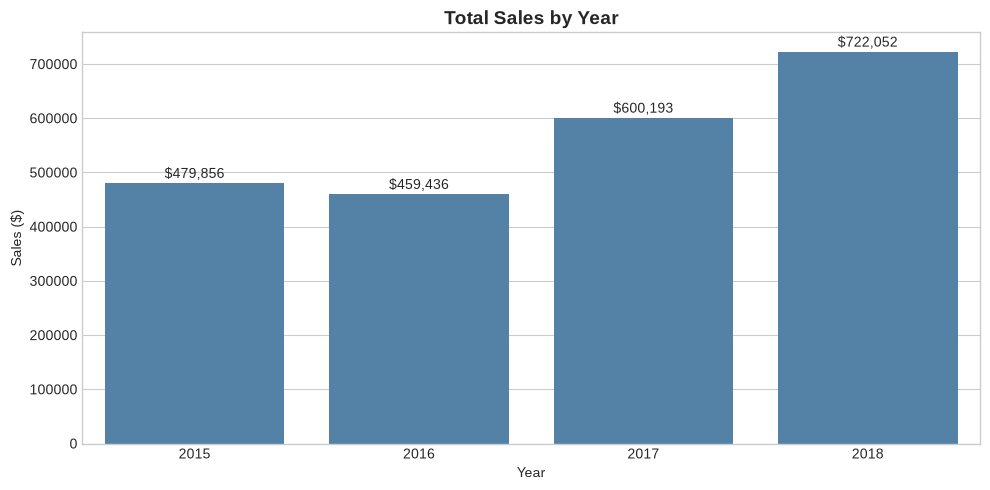


Sales by Year:
 Order_Year     Sales
       2015 479856.21
       2016 459436.01
       2017 600192.55
       2018 722052.02


In [21]:
# Sales by Year
sales_by_year = df.groupby('Order_Year')['Sales'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=sales_by_year, x='Order_Year', y='Sales', color='steelblue')
plt.title('Total Sales by Year', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Sales ($)')
plt.ticklabel_format(style='plain', axis='y')

# Add value labels on bars
for i, row in sales_by_year.iterrows():
    plt.text(i, row['Sales'] + 10000, f"${row['Sales']:,.0f}", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

print("\nSales by Year:")
print(sales_by_year.to_string(index=False))

In [22]:
# Year-over-Year Growth
sales_by_year['YoY_Growth_%'] = sales_by_year['Sales'].pct_change() * 100
print("Year-over-Year Growth:")
print(sales_by_year.round(2).to_string(index=False))

Year-over-Year Growth:
 Order_Year     Sales  YoY_Growth_%
       2015 479856.21           NaN
       2016 459436.01         -4.26
       2017 600192.55         30.64
       2018 722052.02         20.30


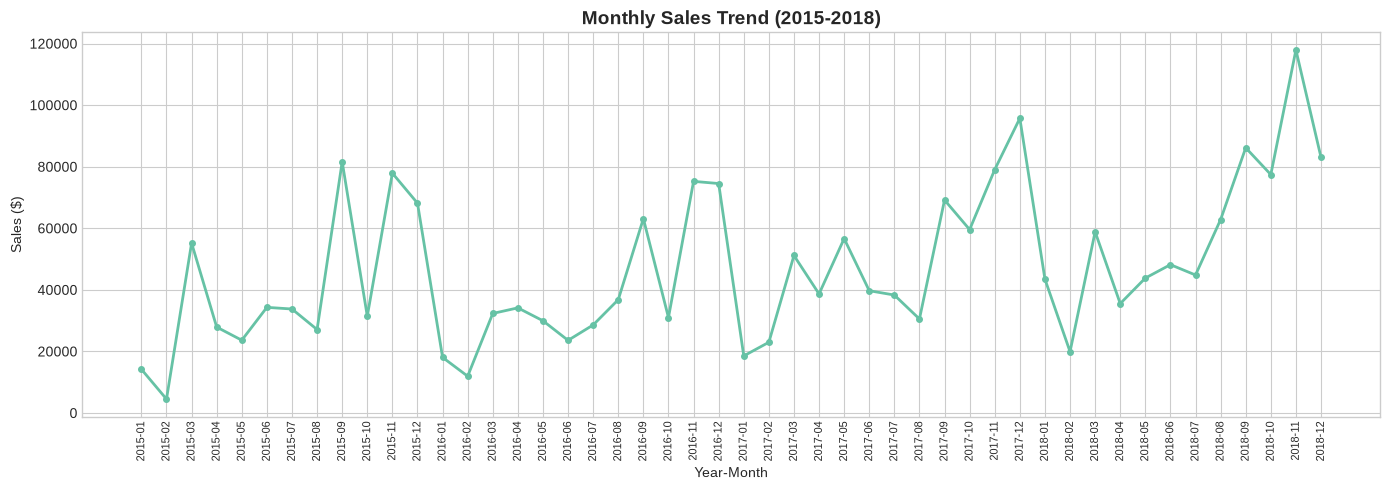

In [23]:
# Monthly Sales Trend
monthly_sales = df.groupby(['Order_Year', 'Order_Month'])['Sales'].sum().reset_index()
monthly_sales['Year_Month'] = monthly_sales['Order_Year'].astype(str) + '-' + monthly_sales['Order_Month'].astype(str).str.zfill(2)

plt.figure(figsize=(14, 5))
plt.plot(monthly_sales['Year_Month'], monthly_sales['Sales'], marker='o', linewidth=2, markersize=4)
plt.title('Monthly Sales Trend (2015-2018)', fontsize=14, fontweight='bold')
plt.xlabel('Year-Month')
plt.ylabel('Sales ($)')
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

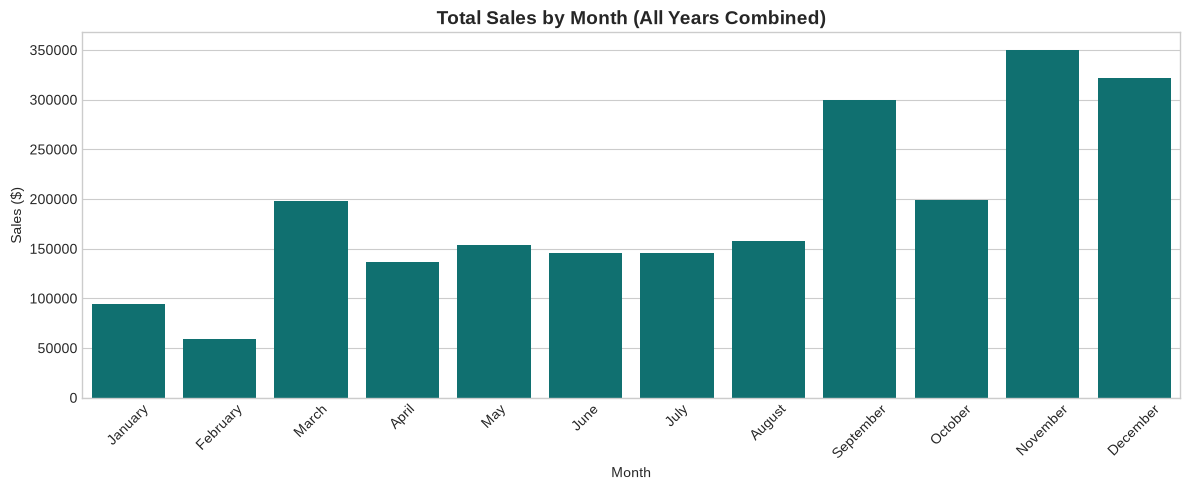


Sales by Month:
Order_Month_Name
January      94291.63
February     59371.12
March       197573.59
April       136283.00
May         154086.72
June        145837.52
July        145535.69
August      157315.93
September   300103.41
October     199496.29
November    350161.71
December    321480.17
Name: Sales, dtype: float64


In [24]:
# Sales by Month (seasonality)
sales_by_month = df.groupby('Order_Month_Name')['Sales'].sum().reindex([
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
])

plt.figure(figsize=(12, 5))
sns.barplot(x=sales_by_month.index, y=sales_by_month.values, color='teal')
plt.title('Total Sales by Month (All Years Combined)', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nSales by Month:")
print(sales_by_month.round(2))

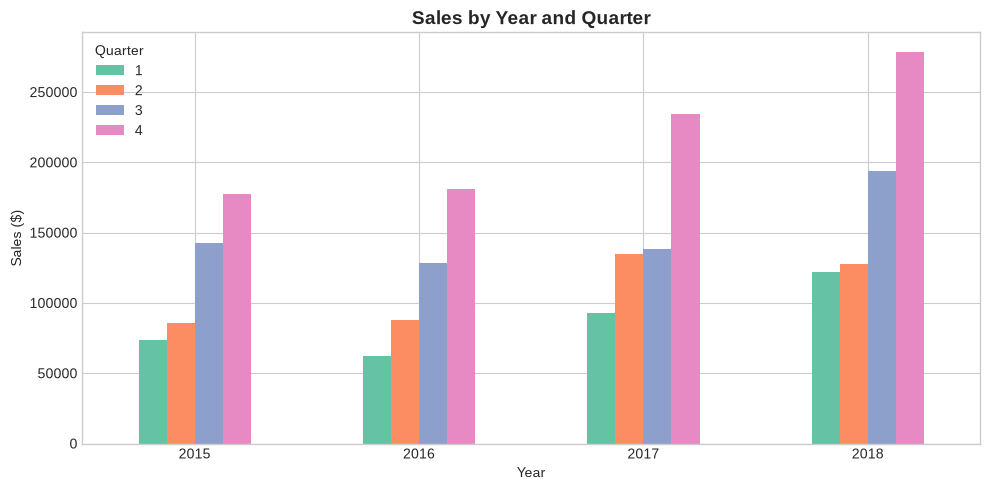


Sales by Year and Quarter:
Order_Quarter         1         2         3         4
Order_Year                                           
2015           73931.40  85874.09 142522.61 177528.11
2016           62357.69  87713.37 128560.21 180804.74
2017           92686.36 135061.16 138056.37 234388.65
2018          122260.88 127558.62 193815.84 278416.68


In [25]:
# Sales by Quarter
sales_by_quarter = df.groupby(['Order_Year', 'Order_Quarter'])['Sales'].sum().unstack()

sales_by_quarter.plot(kind='bar', figsize=(10, 5))
plt.title('Sales by Year and Quarter', fontsize=14, fontweight='bold')
plt.xlabel('Year')
plt.ylabel('Sales ($)')
plt.legend(title='Quarter')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nSales by Year and Quarter:")
print(sales_by_quarter.round(2))

### 3.3 Sales by Geography

Understanding which regions and states generate the most revenue.

/tmp/ipykernel_30421/1444443580.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_region.values, y=sales_by_region.index, palette='viridis')


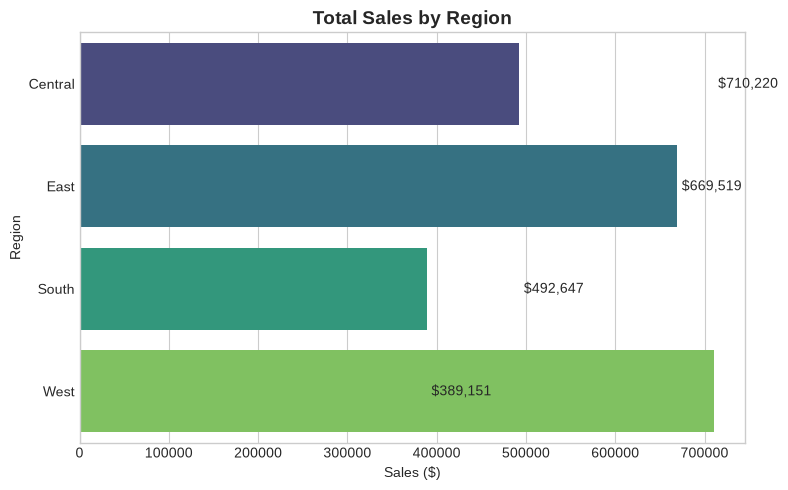


Sales by Region:
Region
West      710219.68
East      669518.73
Central   492646.91
South     389151.46
Name: Sales, dtype: float64

Percentage of Total Sales:
Region
West      31.40
East      29.60
Central   21.80
South     17.20
Name: Sales, dtype: float64


In [26]:
# Sales by Region
sales_by_region = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=sales_by_region.values, y=sales_by_region.index, palette='viridis')
plt.title('Total Sales by Region', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('Region')

for i, v in enumerate(sales_by_region.values):
    plt.text(v + 5000, i, f"${v:,.0f}", va='center')

plt.tight_layout()
plt.show()

print("\nSales by Region:")
print(sales_by_region.round(2))
print("\nPercentage of Total Sales:")
print((sales_by_region / total_sales * 100).round(1))

/tmp/ipykernel_30421/2331107216.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_states.values, y=top_states.index, palette='Blues_r')


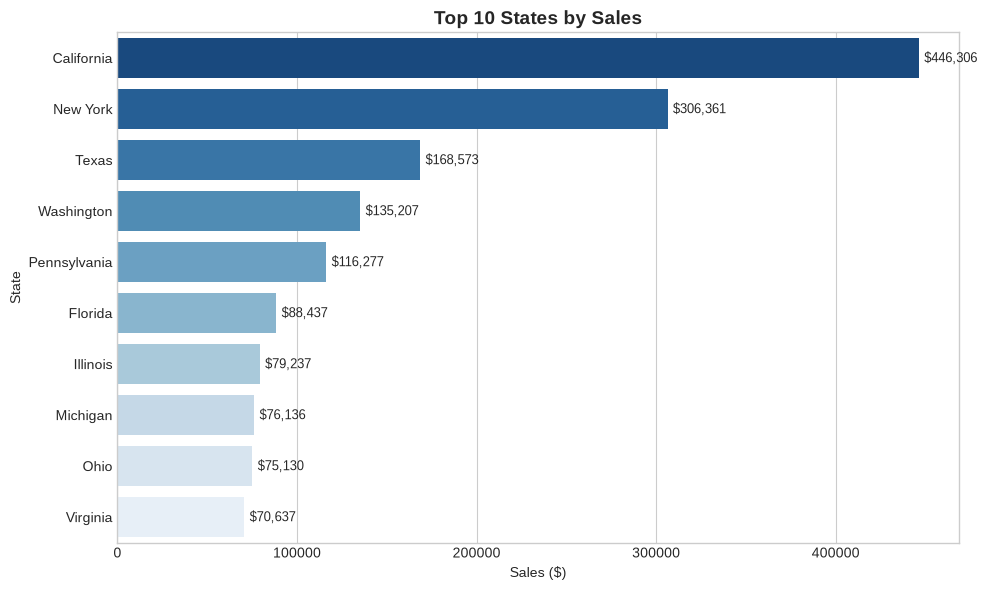


Top 10 States by Sales:
State
California     446306.46
New York       306361.15
Texas          168572.53
Washington     135206.85
Pennsylvania   116276.65
Florida         88436.53
Illinois        79236.52
Michigan        76136.07
Ohio            75130.35
Virginia        70636.72
Name: Sales, dtype: float64


In [27]:
# Top 10 States by Sales
top_states = df.groupby('State')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_states.values, y=top_states.index, palette='Blues_r')
plt.title('Top 10 States by Sales', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('State')

for i, v in enumerate(top_states.values):
    plt.text(v + 3000, i, f"${v:,.0f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("\nTop 10 States by Sales:")
print(top_states.round(2))

In [30]:
# Bottom 5 States by Sales
bottom_states = df.groupby('State')['Sales'].sum().sort_values(ascending=True).head(5)
print("Bottom 5 States by Sales:")
print(bottom_states.round(2))

Bottom 5 States by Sales:
State
North Dakota     919.91
West Virginia   1209.82
Maine           1270.53
South Dakota    1315.56
Wyoming         1603.14
Name: Sales, dtype: float64


### 3.4 Sales by Customer Segment

/tmp/ipykernel_30421/183384438.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_segment.index, y=sales_by_segment.values, ax=axes[0], palette='Set2')


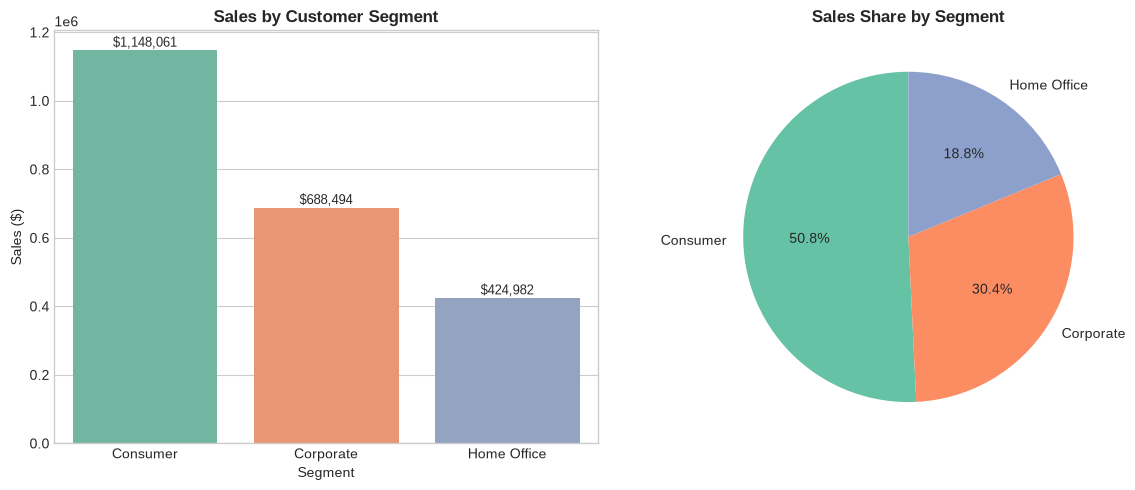


Sales by Segment:
Segment
Consumer      1148060.53
Corporate      688494.07
Home Office    424982.18
Name: Sales, dtype: float64

Number of Customers per Segment:
Segment
Consumer       409
Corporate      236
Home Office    148
Name: Customer ID, dtype: int64


In [31]:
# Sales by Segment
sales_by_segment = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Bar chart
sns.barplot(x=sales_by_segment.index, y=sales_by_segment.values, ax=axes[0], palette='Set2')
axes[0].set_title('Sales by Customer Segment', fontweight='bold')
axes[0].set_ylabel('Sales ($)')

for i, v in enumerate(sales_by_segment.values):
    axes[0].text(i, v + 10000, f"${v:,.0f}", ha='center', fontsize=9)

# Pie chart
axes[1].pie(sales_by_segment.values, labels=sales_by_segment.index, autopct='%1.1f%%',
            startangle=90, colors=sns.color_palette('Set2'))
axes[1].set_title('Sales Share by Segment', fontweight='bold')

plt.tight_layout()
plt.show()

print("\nSales by Segment:")
print(sales_by_segment.round(2))
print("\nNumber of Customers per Segment:")
print(df.groupby('Segment')['Customer ID'].nunique())

### 3.5 Sales by Product Category & Sub-Category

/tmp/ipykernel_30421/2157338490.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_category.index, y=sales_by_category.values, palette='coolwarm')


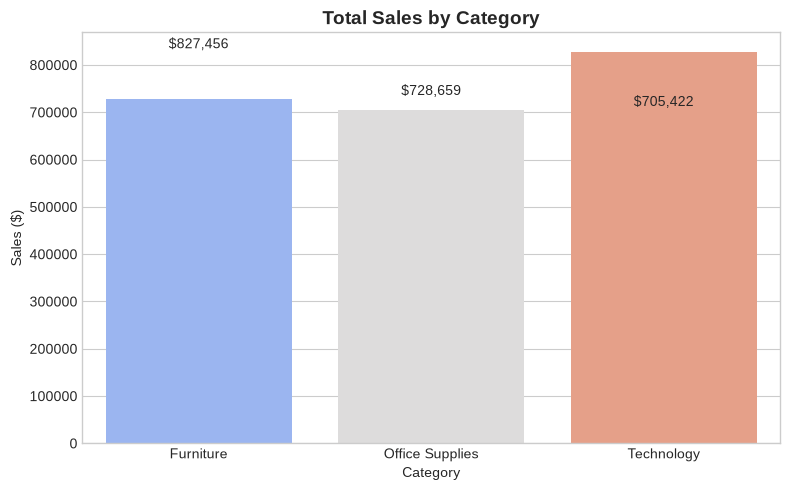


Sales by Category:
Category
Technology        827455.87
Furniture         728658.58
Office Supplies   705422.33
Name: Sales, dtype: float64

Percentage:
Category
Technology        36.60
Furniture         32.20
Office Supplies   31.20
Name: Sales, dtype: float64


In [32]:
# Sales by Category
sales_by_category = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
sns.barplot(x=sales_by_category.index, y=sales_by_category.values, palette='coolwarm')
plt.title('Total Sales by Category', fontsize=14, fontweight='bold')
plt.ylabel('Sales ($)')

for i, v in enumerate(sales_by_category.values):
    plt.text(i, v + 8000, f"${v:,.0f}", ha='center')

plt.tight_layout()
plt.show()

print("\nSales by Category:")
print(sales_by_category.round(2))
print("\nPercentage:")
print((sales_by_category / total_sales * 100).round(1))

/tmp/ipykernel_30421/1531958303.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=sales_by_subcat.values, y=sales_by_subcat.index, palette='magma')


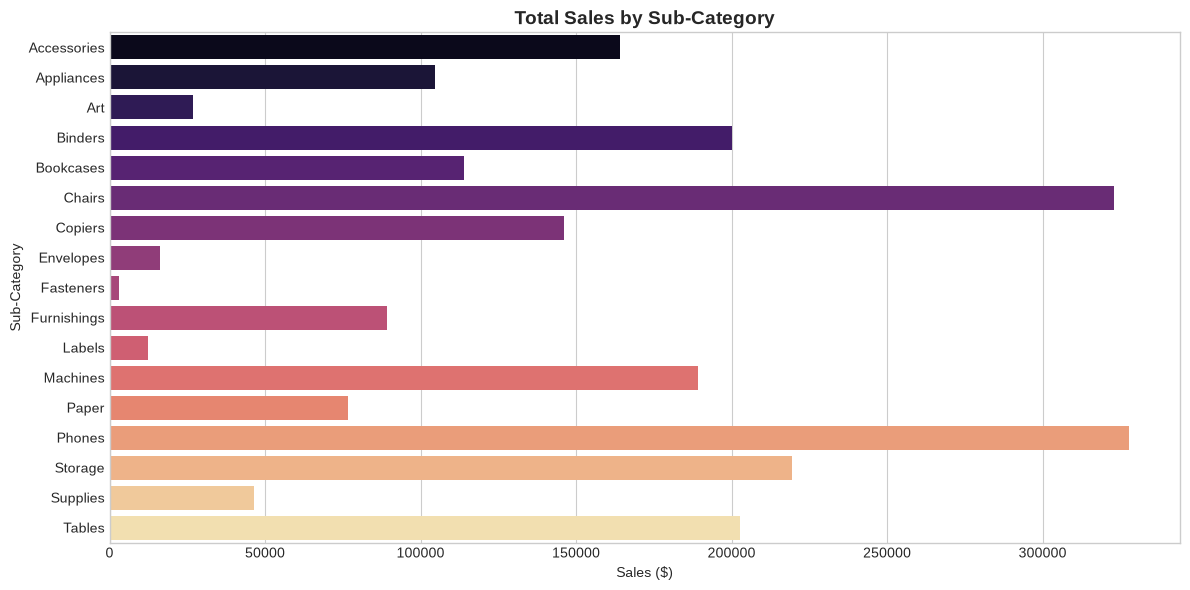


Sales by Sub-Category:
Sub-Category
Phones        327782.45
Chairs        322822.73
Storage       219343.39
Tables        202810.63
Binders       200028.78
Machines      189238.63
Accessories   164186.70
Copiers       146248.09
Bookcases     113813.20
Appliances    104618.40
Furnishings    89212.02
Paper          76828.30
Supplies       46420.31
Art            26705.41
Envelopes      16128.05
Labels         12347.73
Fasteners       3001.96
Name: Sales, dtype: float64


In [33]:
# Sales by Sub-Category
sales_by_subcat = df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(x=sales_by_subcat.values, y=sales_by_subcat.index, palette='magma')
plt.title('Total Sales by Sub-Category', fontsize=14, fontweight='bold')
plt.xlabel('Sales ($)')
plt.ylabel('Sub-Category')
plt.tight_layout()
plt.show()

print("\nSales by Sub-Category:")
print(sales_by_subcat.round(2))

In [34]:
# Category + Sub-Category breakdown
cat_subcat = df.groupby(['Category', 'Sub-Category'])['Sales'].sum().reset_index()
cat_subcat = cat_subcat.sort_values(['Category', 'Sales'], ascending=[True, False])

print("Sales by Category and Sub-Category:")
print(cat_subcat.to_string(index=False))

Sales by Category and Sub-Category:
       Category Sub-Category     Sales
      Furniture       Chairs 322822.73
      Furniture       Tables 202810.63
      Furniture    Bookcases 113813.20
      Furniture  Furnishings  89212.02
Office Supplies      Storage 219343.39
Office Supplies      Binders 200028.79
Office Supplies   Appliances 104618.40
Office Supplies        Paper  76828.30
Office Supplies     Supplies  46420.31
Office Supplies          Art  26705.41
Office Supplies    Envelopes  16128.05
Office Supplies       Labels  12347.73
Office Supplies    Fasteners   3001.96
     Technology       Phones 327782.45
     Technology     Machines 189238.63
     Technology  Accessories 164186.70
     Technology      Copiers 146248.09


### 3.6 Shipping Analysis

Shipping Mode Statistics:
                Orders      Sales  Avg_Shipping_Days  Line_Items
Ship Mode                                                       
Standard Class    2945 1340831.31               5.01        5859
Second Class       944  449914.18               3.25        1902
First Class        772  345572.26               2.18        1501
Same Day           261  125219.04               0.04         538


/tmp/ipykernel_30421/3338576429.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ship_mode_stats.index, y=ship_mode_stats['Sales'], ax=axes[0], palette='Set3')
/tmp/ipykernel_30421/3338576429.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ship_mode_stats.index, y=ship_mode_stats['Avg_Shipping_Days'], ax=axes[1], palette='Set3')


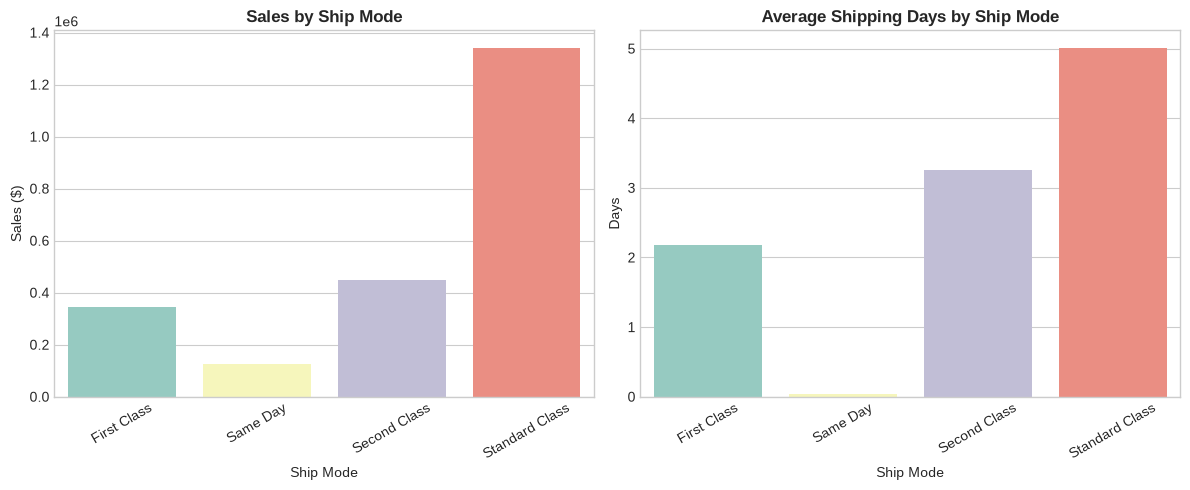

In [35]:
# Ship Mode distribution and sales
ship_mode_stats = df.groupby('Ship Mode').agg(
    Orders=('Order ID', 'nunique'),
    Sales=('Sales', 'sum'),
    Avg_Shipping_Days=('Shipping_Days', 'mean'),
    Line_Items=('Row ID', 'count')
).round(2).sort_values('Sales', ascending=False)

print("Shipping Mode Statistics:")
print(ship_mode_stats)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x=ship_mode_stats.index, y=ship_mode_stats['Sales'], ax=axes[0], palette='Set3')
axes[0].set_title('Sales by Ship Mode', fontweight='bold')
axes[0].set_ylabel('Sales ($)')
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(x=ship_mode_stats.index, y=ship_mode_stats['Avg_Shipping_Days'], ax=axes[1], palette='Set3')
axes[1].set_title('Average Shipping Days by Ship Mode', fontweight='bold')
axes[1].set_ylabel('Days')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

### 3.7 Top Customers & Top Products

In [36]:
# Top 10 Customers by Sales
top_customers = df.groupby(['Customer ID', 'Customer Name', 'Segment'])['Sales'].sum()\
                  .sort_values(ascending=False).head(10).reset_index()

print("Top 10 Customers by Sales:")
print(top_customers.to_string(index=False))

Top 10 Customers by Sales:
Customer ID      Customer Name     Segment    Sales
   SM-20320        Sean Miller Home Office 25043.05
   TC-20980       Tamara Chand   Corporate 19052.22
   RB-19360       Raymond Buch    Consumer 15117.34
   TA-21385       Tom Ashbrook Home Office 14595.62
   AB-10105      Adrian Barton    Consumer 14473.57
   KL-16645       Ken Lonsdale    Consumer 14175.23
   SC-20095       Sanjit Chand    Consumer 14142.33
   HL-15040       Hunter Lopez    Consumer 12873.30
   SE-20110       Sanjit Engle    Consumer 12209.44
   CC-12370 Christopher Conant    Consumer 12129.07


In [37]:
# Top 10 Products by Sales
top_products = df.groupby(['Product ID', 'Product Name', 'Category', 'Sub-Category'])['Sales'].sum()\
                 .sort_values(ascending=False).head(10).reset_index()

print("Top 10 Products by Sales:")
print(top_products.to_string(index=False))

Top 10 Products by Sales:
     Product ID                                                                Product Name        Category Sub-Category    Sales
TEC-CO-10004722                                       Canon imageCLASS 2200 Advanced Copier      Technology      Copiers 61599.82
OFF-BI-10003527 Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind Office Supplies      Binders 27453.38
TEC-MA-10002412                       Cisco TelePresence System EX90 Videoconferencing Unit      Technology     Machines 22638.48
FUR-CH-10002024                                HON 5400 Series Task Chairs for Big and Tall       Furniture       Chairs 21870.58
OFF-BI-10001359                                  GBC DocuBind TL300 Electric Binding System Office Supplies      Binders 19823.48
OFF-BI-10000545                            GBC Ibimaster 500 Manual ProClick Binding System Office Supplies      Binders 19024.50
TEC-CO-10001449                                        Hewlett P

### 3.8 Additional Useful Views

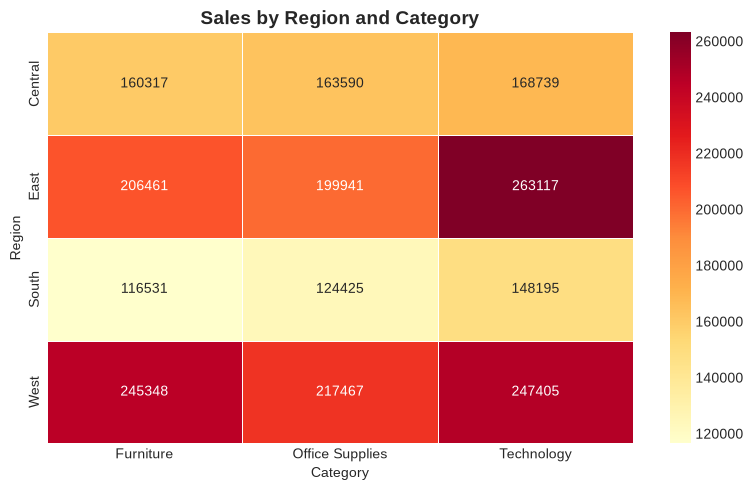


Sales by Region and Category:
Category  Furniture  Office Supplies  Technology
Region                                          
Central   160317.00        163590.00   168739.00
East      206461.00        199941.00   263117.00
South     116531.00        124425.00   148195.00
West      245348.00        217467.00   247405.00


In [38]:
# Sales by Region and Category (heatmap style)
region_category = df.pivot_table(values='Sales', index='Region', columns='Category', aggfunc='sum')

plt.figure(figsize=(8, 5))
sns.heatmap(region_category, annot=True, fmt='.0f', cmap='YlOrRd', linewidths=0.5)
plt.title('Sales by Region and Category', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nSales by Region and Category:")
print(region_category.round(0))

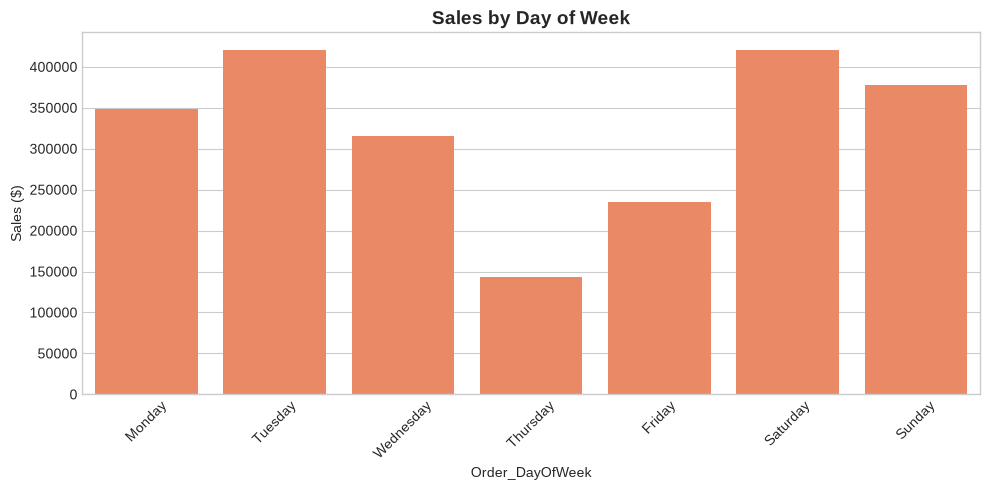


Sales by Day of Week:
Order_DayOfWeek
Monday      348791.55
Tuesday     420535.92
Wednesday   315888.97
Thursday    142839.24
Friday      234710.84
Saturday    420901.48
Sunday      377868.78
Name: Sales, dtype: float64


In [39]:
# Sales by Day of Week
dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sales_by_dow = df.groupby('Order_DayOfWeek')['Sales'].sum().reindex(dow_order)

plt.figure(figsize=(10, 5))
sns.barplot(x=sales_by_dow.index, y=sales_by_dow.values, color='coral')
plt.title('Sales by Day of Week', fontsize=14, fontweight='bold')
plt.ylabel('Sales ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nSales by Day of Week:")
print(sales_by_dow.round(2))

---

## Insights & Recommendations

Based on the exploratory analysis and SQL results, here are the key business insights and actionable recommendations.

### Insight 1: Strong Sales Growth After 2016

**Finding:**  
Sales declined slightly in 2016 (–4.3%) but then grew strongly:  
- 2017: **+30.6%**  
- 2018: **+20.3%**  

Total sales reached **$722,052** in 2018 (highest year).

**Why it matters:**  
The business is on a positive growth trajectory after a temporary dip.

**Recommendation:**  
- Investigate what changed in 2017 (new products, marketing, expansion) and double-down on those successful actions.  
- Set growth targets for 2019 based on the 20%+ trend.  
- Monitor monthly performance closely to detect any slowdown early.

### Insight 2: Heavy Geographic Concentration – Risk & Opportunity

**Finding:**  
- **West** (31.4%) and **East** (29.6%) regions generate more than 60% of total sales.  
- Just **three states** (California, New York, Texas) account for **40.7%** of all sales.  
- California alone contributes almost **20%** of total revenue.  
- South region is the weakest (only 17.2%).

**Why it matters:**  
Over-dependence on a few states creates risk. At the same time, weaker regions represent growth opportunities.

**Recommendation:**  
- Develop targeted campaigns for the **South** and underperforming Central states.  
- Protect and deepen the relationship with top customers in California and New York.  
- Analyse why South underperforms (product mix, shipping times, competition) and create a specific action plan.

### Insight 3: Consumer Segment Dominates – Corporate & Home Office Are Under-leveraged

**Finding:**  
- **Consumer** segment generates **50.8%** of sales.  
- Corporate: 30.4%  
- Home Office: only **18.8%**

**Why it matters:**  
While Consumer is healthy, Corporate and especially Home Office customers have lower contribution. Home Office has grown in importance in recent years and may represent an untapped opportunity.

**Recommendation:**  
- Create dedicated offers and marketing for the **Home Office** segment (bundles, ergonomic furniture, technology packages).  
- Develop loyalty or volume-discount programs for **Corporate** clients to increase their share.  
- Analyse the average order value and purchase frequency by segment to refine the strategy.

### Insight 4: Technology Leads, but Phones & Chairs Drive a Large Share of Revenue

**Finding:**  
- **Technology** is the top category (**36.6%** of sales).  
- Furniture and Office Supplies are very close to each other (~32% and 31%).  
- Two sub-categories alone — **Phones** and **Chairs** — generate over **$650,000** (nearly 29% of total sales).

**Why it matters:**  
A large portion of revenue depends on a small number of product groups. This is both a strength (clear winners) and a risk (if demand for phones or chairs drops).

**Recommendation:**  
- Maintain strong inventory and promotion focus on Phones and Chairs.  
- Explore cross-selling opportunities (e.g., phone accessories with phones, desks with chairs).  
- Identify rising sub-categories that could become the next growth engines.  
- Review low-performing sub-categories for possible discontinuation or repositioning.

### Insight 5: Strong Seasonality – Q4 (especially Nov–Dec) is Critical

**Finding:**  
- November and December together account for almost **30%** of annual sales.  
- Q4 is consistently the strongest quarter every year.  
- Early months (Jan–Feb) are significantly weaker.

**Why it matters:**  
Cash flow, inventory planning and staffing are heavily affected by this seasonal pattern.

**Recommendation:**  
- Plan inventory and marketing budget with a clear peak in Q4.  
- Launch early holiday promotions (October) to capture more demand.  
- Use the quieter first quarter for customer retention campaigns, product launches and process improvements.  
- Consider special offers in January–February to reduce the seasonal gap.

### Insight 6: Shipping – Standard Class Dominates, Faster Options Are Underused

**Finding:**  
- **Standard Class** is used for ~59% of sales and takes on average **5 days**.  
- First Class (2.2 days) and Same Day (almost 0 days) together represent only ~21% of sales.  
- Shipping performance is relatively consistent across regions.

**Why it matters:**  
Most customers accept slower shipping. There may be an opportunity to increase revenue by promoting faster shipping options (for a premium) or to improve customer satisfaction by reducing Standard Class delivery time.

**Recommendation:**  
- Test a small price premium for First Class / Same Day on high-value orders.  
- Analyse whether faster shipping increases repeat purchase rate.  
- Review logistics partners to see if Standard Class average can be reduced from 5 days toward 3–4 days without major cost increase.

### Summary Table of Insights & Recommendations

| # | Insight | Key Evidence | Main Recommendation |
|---|---------|--------------|---------------------|
| 1 | Strong growth after 2016 | +30.6% in 2017, +20.3% in 2018 | Scale what worked in 2017-2018 |
| 2 | Geographic concentration | CA + NY + TX = 40.7% of sales | Expand in South & protect top states |
| 3 | Consumer dominates | Consumer = 50.8% | Grow Home Office & Corporate segments |
| 4 | Phones & Chairs are critical | ~29% of total sales | Focus inventory & cross-sell on these |
| 5 | Heavy Q4 seasonality | Nov+Dec ≈ 30% of sales | Plan inventory & campaigns around Q4 |
| 6 | Standard Class dominates shipping | 59% of sales, 5 days avg | Test premium fast shipping & improve Standard |

---

